# 03 Lift: naive view, estimated lift, effect of seeing an ad, and money (findings 2 to 5 and 7)

Write-ups: `docs/lift.md`, `docs/attribution_vs_incrementality.md`, `docs/money.md`.

*All absolute numbers describe this benchmark file: Criteo sub-sampled it so its real incrementality can't be recovered.*

In [1]:
from pathlib import Path
import json

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from incrementality.style import PAL, SOURCE, SOURCE_IOWA, apply, finish

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRITEO = (ROOT / "data" / "processed" / "criteo_uplift.parquet").as_posix()
results = lambda name: json.loads((ROOT / "results" / f"{name}.json").read_text(encoding="utf-8"))
show = lambda name: display(Image(filename=str(ROOT / "figures" / name), width=900))
pd.set_option("display.float_format", "{:,.4f}".format)
apply()

In [2]:
from linearmodels.iv import IV2SLS

from incrementality.lift import exposed_effect, rate_diff

g = duckdb.sql(f"""SELECT treatment, exposure, count(*) AS n, sum(conversion) AS conv, sum(visit) AS visit
                    FROM '{CRITEO}' GROUP BY ALL""").df().set_index(["treatment", "exposure"])
e, nt, c = g.loc[(1, 1)], g.loc[(1, 0)], g.loc[(0, 0)]
unexposed = nt + c

## Finding 2: the naive view (what a dashboard does)

In [3]:
naive = rate_diff(e["conv"], e["n"], unexposed["conv"], unexposed["n"])
print(f"Saw an ad: {naive.rate_t:.2%}   Didn't: {naive.rate_c:.2%}   Looks like {naive.rate_t / naive.rate_c:.0f}x")

Saw an ad: 5.38%   Didn't: 0.13%   Looks like 41x


## Finding 3: the estimated lift for the whole treatment group (intent-to-treat)

In [4]:
itt = rate_diff(e["conv"] + nt["conv"], e["n"] + nt["n"], c["conv"], c["n"])
print(f"Raw: {itt.rel:+.1%} (95% interval {itt.rel_lo:+.1%} to {itt.rel_hi:+.1%})")
a = results("lift_aipw")
print(f"Adjusted for the features (doubly robust, cross-fitted; from results): "
      f"{a['conversion']['itt']['estimate'] / itt.rate_c:+.1%}")

Raw: +59.4% (95% interval +54.4% to +64.7%)
Adjusted for the features (doubly robust, cross-fitted; from results): +52.5%


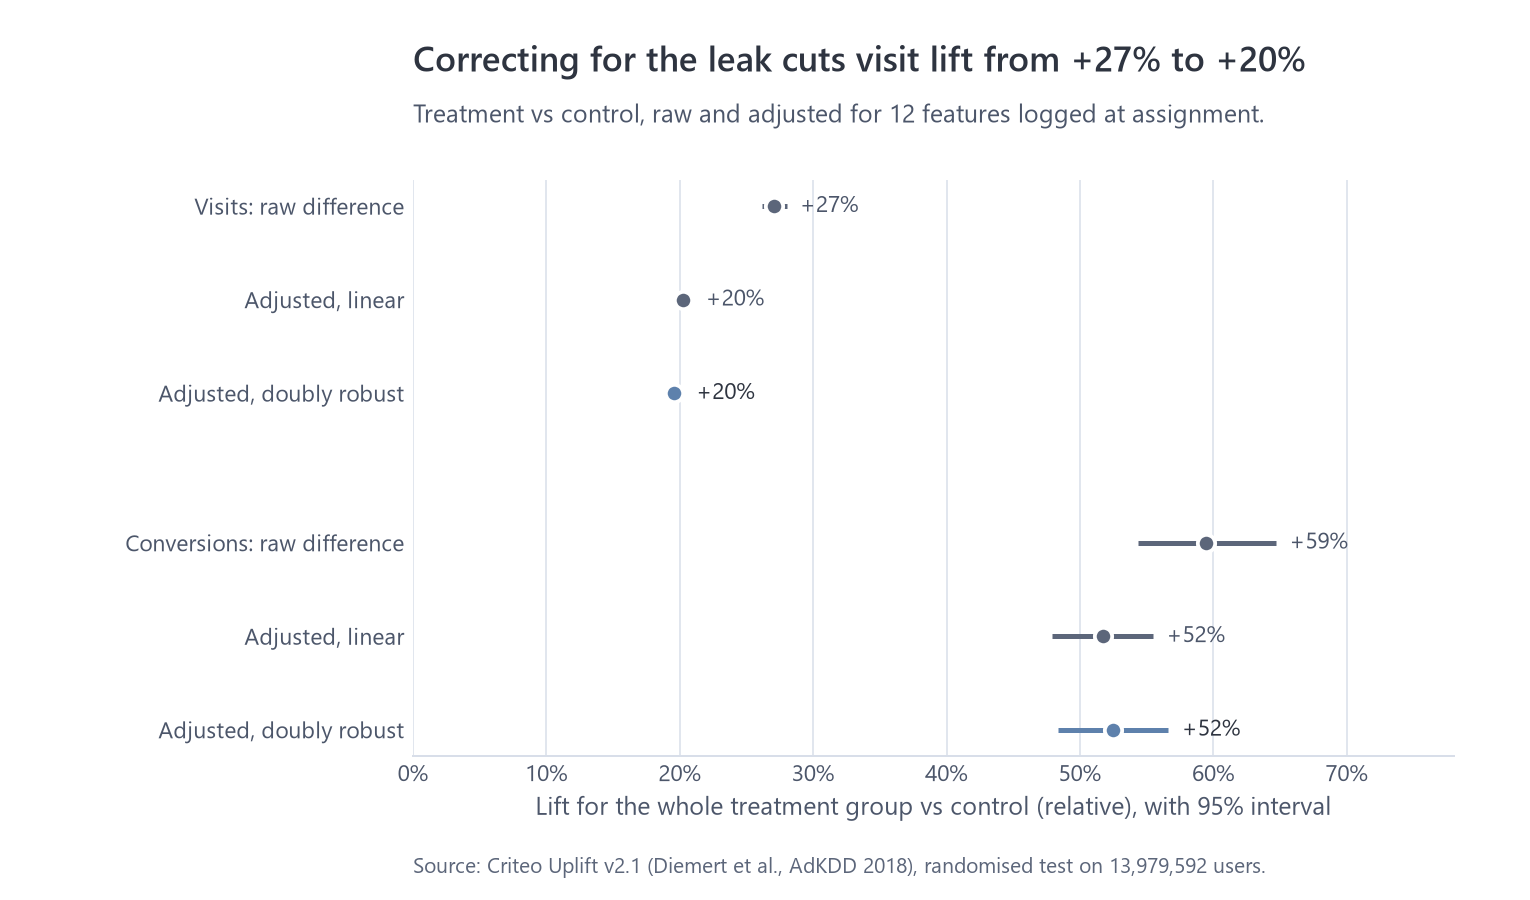

In [5]:
show("lift/raw_vs_adjusted.png")

## Finding 4: the effect of actually seeing an ad

Random assignment shifts who sees an ad, and nobody in control can see one, so it works as an *instrument*: effect of seeing an ad = whole-group lift / share who saw one. Two-stage least squares (2SLS) gives the same number with a robust interval.

In [6]:
ex = exposed_effect(e["conv"], e["n"], nt["conv"], nt["n"], c["conv"], c["n"])
cols = duckdb.sql(f"SELECT conversion, exposure, treatment FROM '{CRITEO}'").df().astype(float)
iv = IV2SLS(cols["conversion"], np.ones(len(cols)), cols["exposure"], cols["treatment"]).fit(cov_type="robust")
print(f"Our formula: +{ex.cace * 100:.3f} points   2SLS: +{iv.params['exposure'] * 100:.3f} points")
print(f"Raw: users who saw an ad would have converted at {ex.baseline:.2%} anyway; with the ad {ex.rate_exposed:.2%}")
print(f"Adjusted (from results): {a['conversion']['baseline']:.2%} anyway, so the estimated causal effect is "
      f"{a['conversion']['rate_exposed'] / a['conversion']['baseline']:.1f}x, not {naive.rate_t / naive.rate_c:.0f}x")
del cols

Our formula: +3.196 points   2SLS: +3.196 points
Raw: users who saw an ad would have converted at 2.18% anyway; with the ad 5.38%
Adjusted (from results): 2.49% anyway, so the estimated causal effect is 2.2x, not 41x


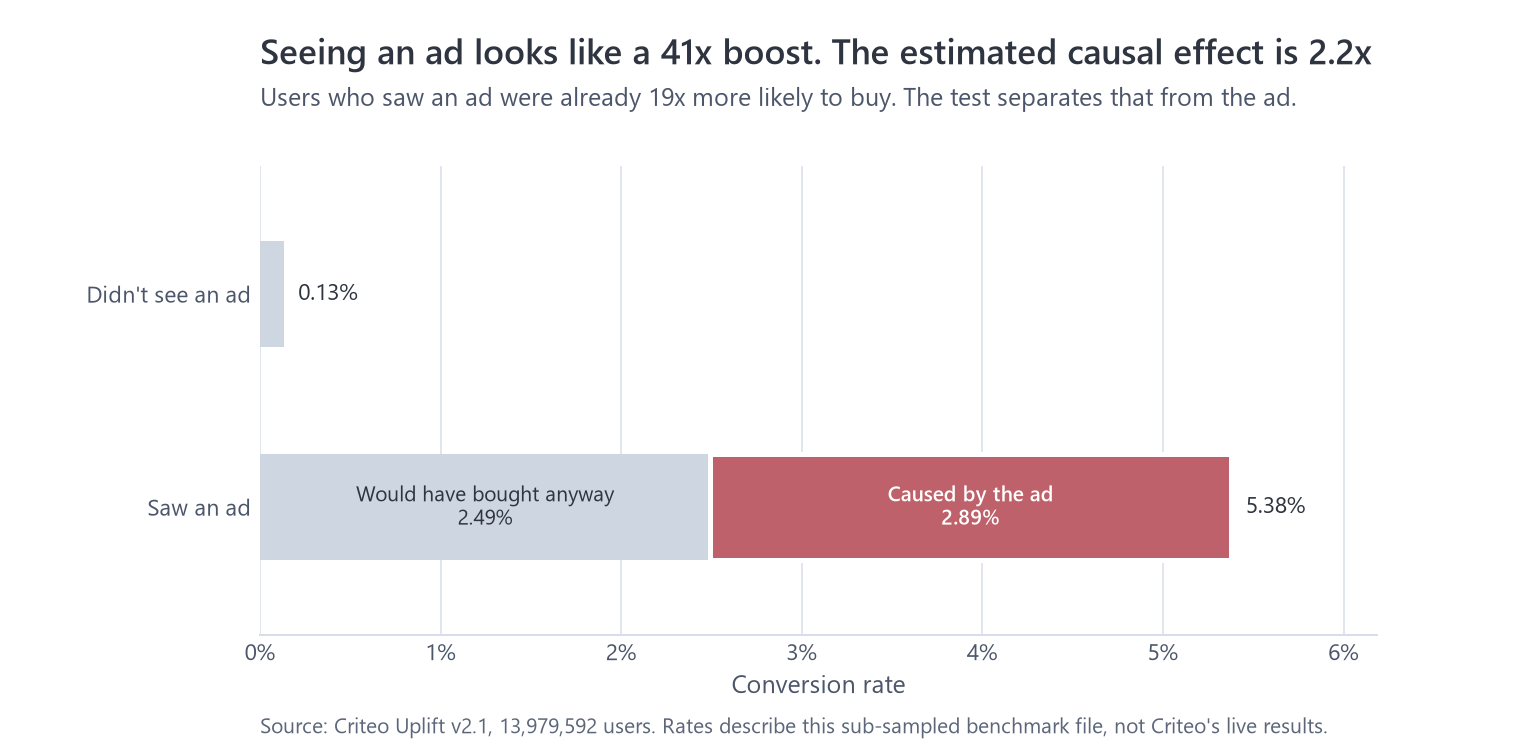

In [7]:
show("lift/naive_vs_caused.png")

### How much does the correction depend on the method?

`sensitivity_analysis.py` (about 20 minutes) re-estimates the lift with two model families and three adjustment styles: doubly robust, weighting only and outcome model only. If weighting balances the features, the propensity model has captured the leak.

In [8]:
sens = results("sensitivity")
print({k: round(v, 4) if isinstance(v, float) else v for k, v in sens["balance"].items()})
pd.DataFrame(sens["rows"]).pivot(index="specification", columns="outcome", values="lift").round(3)

{'raw_max_abs_smd': 0.0488, 'boosting_weighted_max_abs_smd': 0.0023, 'boosting_propensity_p01_p99': [0.8449927979436808, 0.8951143112025685], 'logistic_weighted_max_abs_smd': 0.0011, 'logistic_propensity_p01_p99': [0.8435505620120612, 0.8779976086013789]}


outcome,conversion,visit
specification,,
"Doubly robust, gradient boosting",0.5250,0.1960
"Doubly robust, logistic regression",0.5000,0.1870
Linear adjustment (Lin),0.5170,0.2020
"Outcome model only, gradient boosting",0.5630,0.1940
"Outcome model only, logistic regression",0.5030,0.1870
Raw difference,0.5940,0.2710
"Weighting only (IPW), gradient boosting",0.5120,0.2010
"Weighting only (IPW), logistic regression",0.5130,0.2050


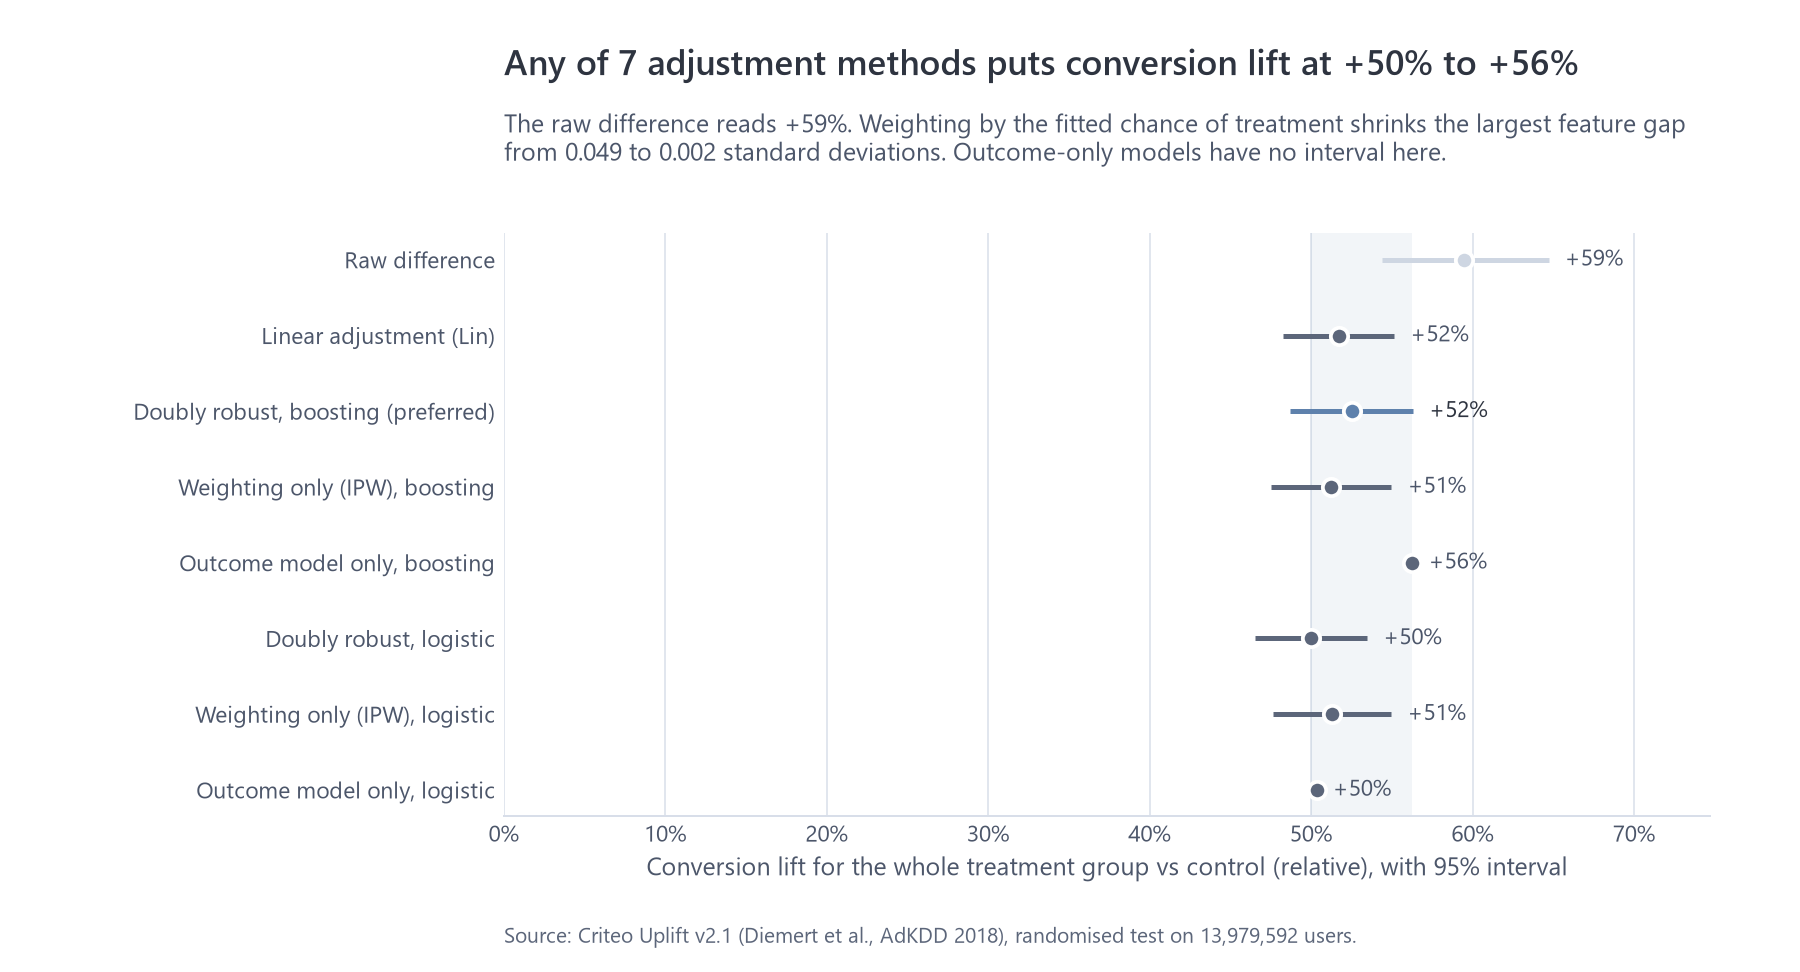

In [9]:
show("lift/sensitivity.png")

## Finding 5: credited vs caused

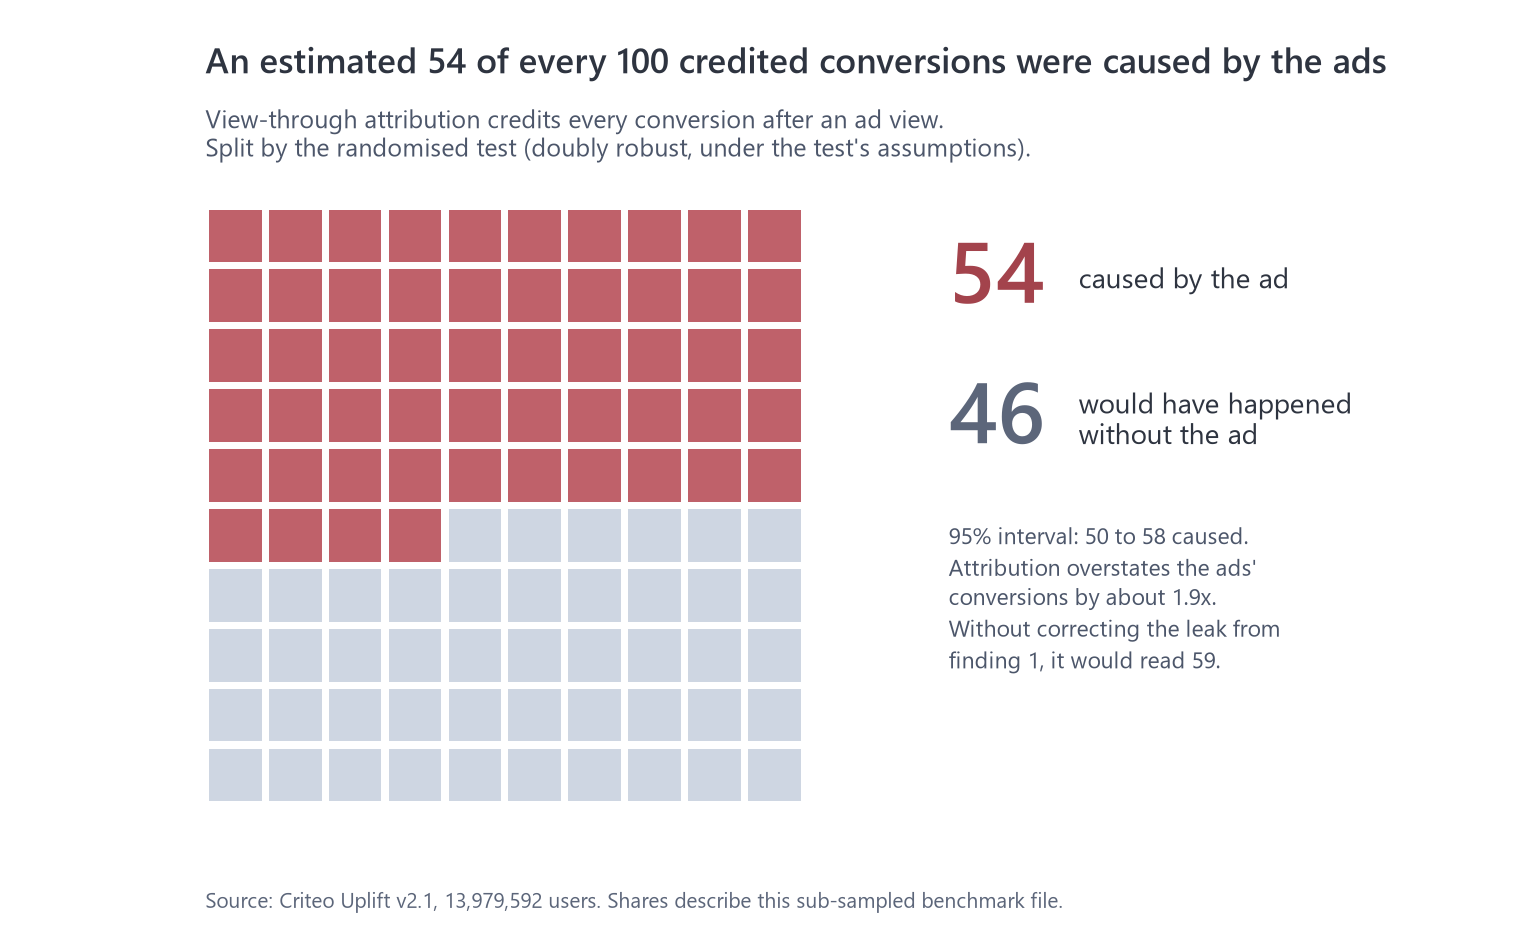

In [10]:
show("attribution/credited_vs_caused.png")

## Finding 7: is it worth the money?

**Scenario analysis, not observed profit.** The data has no prices or costs, so two assumptions are stated openly (a dashboard ROAS of 8 and a 30% margin) and varied in the sensitivity tables in `docs/money.md`.

In [11]:
m = results("money")
b = m["base"]
pd.DataFrame({"profit per £1": [b["dashboard_profit_per_pound"], b["incremental_profit_per_pound"]["estimate"],
                                b["best_half_profit_per_pound"]["estimate"], b["other_half_profit_per_pound"]["estimate"]]},
             index=["what the dashboard implies", "incremental, all spend", "incremental, best half of spend",
                    "incremental, other half"])

,profit per £1
what the dashboard implies,1.4000
"incremental, all spend",0.2879
"incremental, best half of spend",1.1565
"incremental, other half",-0.5825


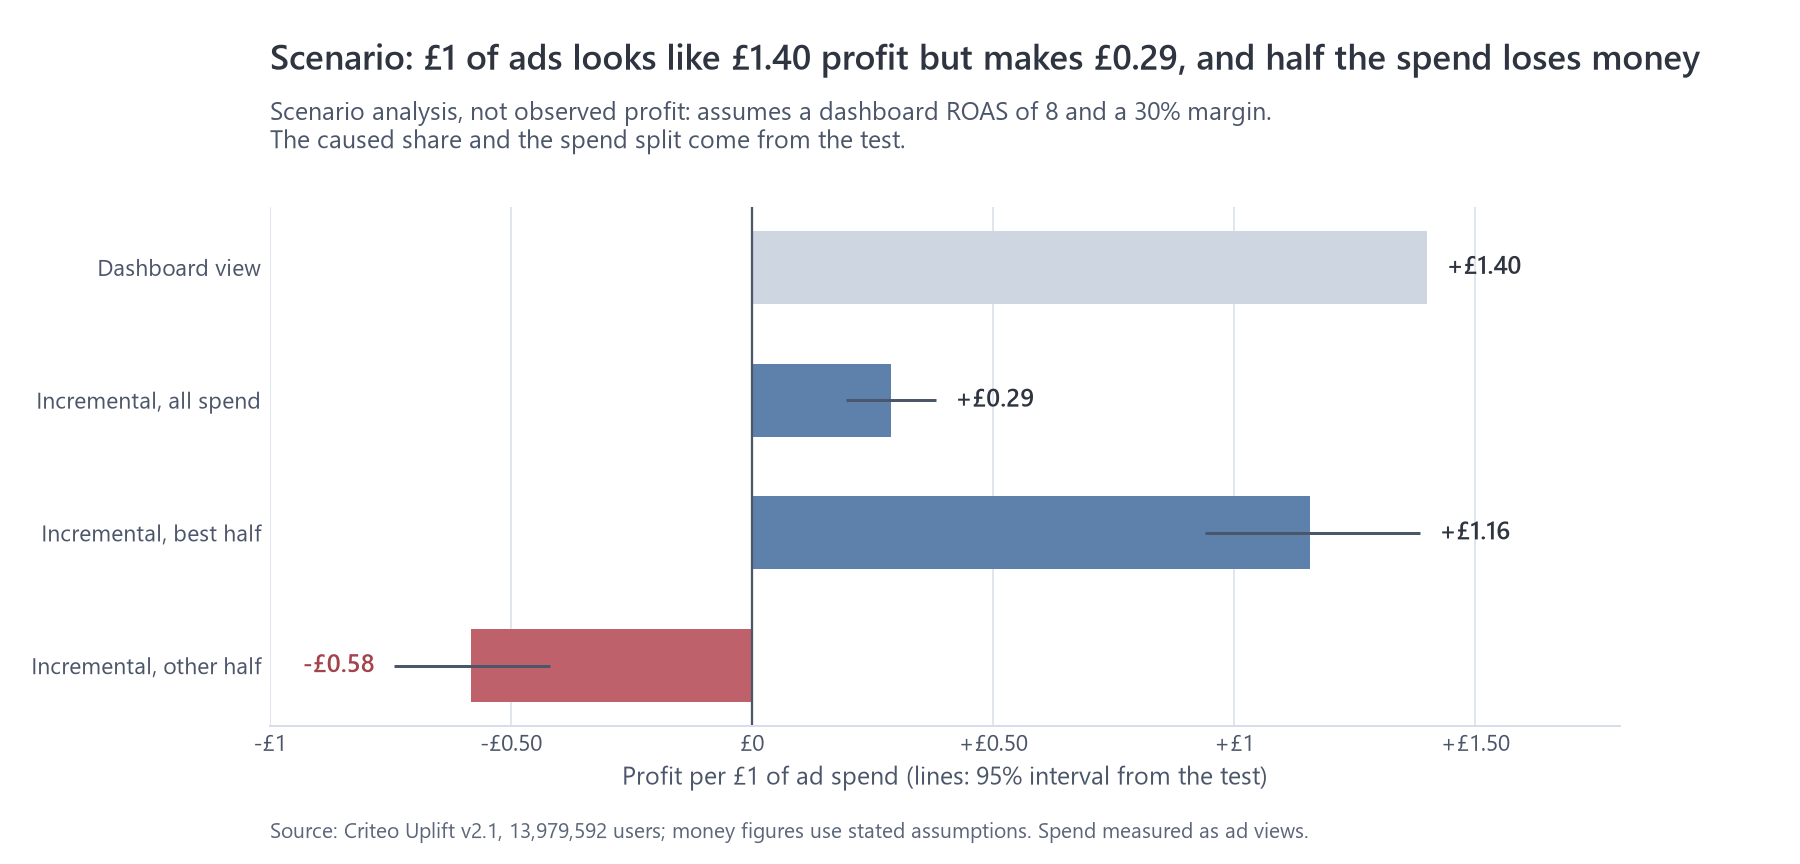

In [12]:
show("money/profit_per_pound.png")